# 10. Monte Carlo Simulation: Forecasting and What-If Decisions

**Procurement Intelligence Platform** | Notebook 10 of 13

Two simulators built from how the business actually works: one for demand, one for the procure-to-pay process. They forecast, quantify uncertainty and answer questions no time-series model can answer.

| | |
|---|---|
| **Inputs** | `fct_weekly_section` (demand components), `fct_requisition_line` (stage durations) |
| **Outputs** | Simulation backtests, calibration, six management scenarios |
| **Skills shown** | Stochastic simulation, uncertainty quantification, decision analysis |

## 1. Why simulate?

A time-series model learns patterns in a number. A simulation reproduces the **mechanism** that creates the number:

* **Demand simulator.** Requisitions come from four drivers (breakdowns, planned maintenance, MRP restock, projects). Each driver is
  simulated with its own statistical behaviour and the results are added up, 2,000 times.
* **Process simulator.** Every open line and every future line travels through the remaining stages (release, RFQ, quotation, approval,
  downpayment, supplier production, goods receipt, payment). Durations are drawn from what actually happened in the last 12 months,
  **conditioned on the time a line has already waited** in its current stage.

The second simulator has a unique power: changing one stage ("approvals twice as fast") and re-running shows the effect on the whole
pipeline. That is decision support, not only forecasting.

In [1]:
import sys, warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from p2p.viz.theme import use_matplotlib, BRAND, SERIES, ORIGIN_COLORS, STATUS, shade_shocks
use_matplotlib()
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

In [2]:
from p2p.data import panel, weekly_section, company_series
from p2p.forecasting import backtest as bt, montecarlo as mc
from p2p.forecasting.registry import load_arena, run_or_load
from p2p.forecasting.metrics import evaluate, seasonal_naive_scale

ws = weekly_section()
df = panel("pr_lines")
train, _ = bt.train_test(df)
scale = seasonal_naive_scale(train)

## 2. The demand simulator

For each section the simulator estimates, using only data before the forecast origin:

| Driver | Distribution | Parameters estimated from history |
|---|---|---|
| Corrective maintenance | Negative binomial (over-dispersed counts) | Recent level (26 weeks, de-seasonalised), monthly seasonal index, shutdown factor, dispersion |
| Planned maintenance | Poisson around the published plan | Lines per planned work order |
| MRP restock | Poisson, different means in MRP and non-MRP weeks | Recent means, budget-push factor, shutdown factor |
| Projects | Bernoulli burst times an empirical burst size | Burst frequency and sizes |

A shared **demand-level multiplier** per simulation represents uncertainty about the current level (all sections busier or quieter at
once). Without it the sections are independent, their errors cancel out and the company-level range is too narrow.

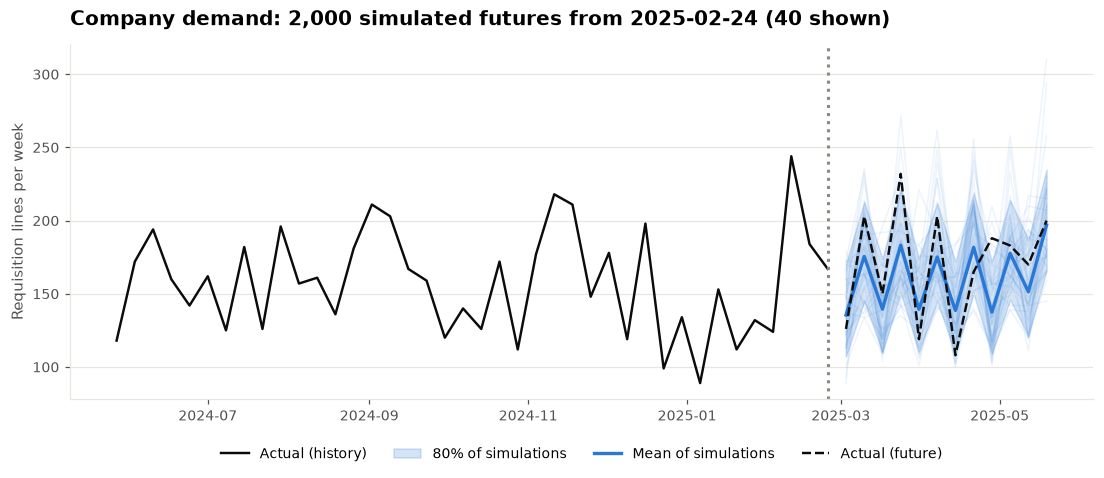

In [3]:
origin = bt.test_cutoffs()[2]
hist = ws[ws.week_start <= origin]
fut = ws[(ws.week_start > origin) & (ws.week_start <= origin + pd.Timedelta(weeks=12))][["section_id", "week_start", "pm_planned_next_3w"]]
sim = mc.DemandSimulator(hist).simulate(fut, n_sims=2000, seed=1)
total = sum(sim.values())                     # company total: (12 weeks, 2000 simulations)
dates = sorted(fut.week_start.unique())
actual = ws.groupby("week_start").pr_lines.sum()

fig, ax = plt.subplots(figsize=(12, 4.2))
h = actual[(actual.index > origin - pd.Timedelta(weeks=40)) & (actual.index <= origin)]
ax.plot(h.index, h.values, color=BRAND["ink"], lw=1.6, label="Actual (history)")
for i in range(40):
    ax.plot(dates, total[:, i], color=SERIES[0], alpha=0.08, lw=1)
ax.fill_between(dates, np.quantile(total, 0.1, axis=1), np.quantile(total, 0.9, axis=1), color=SERIES[0], alpha=0.2, label="80% of simulations")
ax.plot(dates, total.mean(axis=1), color=SERIES[0], lw=2.2, label="Mean of simulations")
ax.plot(dates, actual.reindex(dates).values, color=BRAND["ink"], lw=1.6, ls="--", label="Actual (future)")
ax.axvline(origin, color=BRAND["muted"], ls=":")
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.1)); ax.set_ylabel("Requisition lines per week")
ax.set_title(f"Company demand: 2,000 simulated futures from {origin.date()} (40 shown)")
plt.show()

Each thin line is one possible future. The band shows where 80% of them fall, and the dashed line is what actually happened.

### Calibrating the level uncertainty (validation only)

In [4]:
rows = []
for sigma in [0.0, 0.08, 0.15]:
    def fn(train_, h, cutoff, s=sigma):
        hist_ = ws[ws.week_start <= cutoff]
        fut_ = ws[(ws.week_start > cutoff) & (ws.week_start <= cutoff + pd.Timedelta(weeks=h))][["section_id", "week_start", "pm_planned_next_3w"]]
        sims = mc.DemandSimulator(hist_, level_sigma=s).simulate(fut_, n_sims=1000, seed=int(cutoff.strftime("%Y%m%d")) % 2**31)
        out = []
        for sec, arr in sims.items():
            d = fut_[fut_.section_id == sec].sort_values("week_start").week_start.to_numpy()
            q = np.quantile(arr, [0.025, 0.1, 0.5, 0.9, 0.975], axis=1)
            out.append(pd.DataFrame({"unique_id": sec, "ds": d, "yhat": arr.mean(axis=1), "q0.025": q[0], "q0.1": q[1], "q0.5": q[2], "q0.9": q[3], "q0.975": q[4]}))
        return pd.concat(out)
    rows.append(bt.rolling_origin(fn, df, bt.validation_cutoffs(), f"level sigma = {sigma}"))
display(evaluate(pd.concat(rows), scale)[["model", "MASE", "CRPS", "Coverage80", "Coverage95"]])

,model,MASE,CRPS,Coverage80,Coverage95
0,level sigma = 0.08,0.717,2.279,0.799,0.946
1,level sigma = 0.0,0.718,2.292,0.795,0.949
2,level sigma = 0.15,0.719,2.269,0.805,0.953


**What we see.** At section level the setting hardly matters: accuracy and coverage are almost identical (80% coverage between 0.795
and 0.805), because the week-to-week noise of a single section dwarfs the level uncertainty. The shared multiplier matters for **totals**:
without it, the 12 independent sections would cancel each other out and the company-level range would be too narrow. The production
setting is 0.08, chosen on 2024 data only.

## 3. Demand simulator against every other model

In [5]:
val, _ = load_arena("inflow", "validation")
test, secs = load_arena("inflow", "test")
tr_scale = scale
summary = evaluate(val, tr_scale)[["model", "MASE"]].rename(columns={"MASE": "MASE validation 2024"}).merge(
          evaluate(test, tr_scale)[["model", "MASE", "WAPE", "Bias", "CRPS", "Coverage80"]].rename(columns={"MASE": "MASE test 2025"}), on="model")
display(summary.sort_values("MASE test 2025").head(8))

,model,MASE validation 2024,MASE test 2025,WAPE,Bias,CRPS,Coverage80
0,Monte Carlo (structural demand),0.718,0.875,0.346,-0.085,2.829,0.797
3,Random Forest,0.760,0.893,0.353,-0.061,2.820,0.796
1,LightGBM,0.750,0.899,0.355,-0.074,2.846,0.799
11,N-BEATS,0.799,0.910,0.361,-0.134,3.132,0.792
2,XGBoost,0.751,0.914,0.361,-0.062,2.876,0.790
5,Chronos-Bolt (zero-shot),0.767,0.929,0.367,-0.200,3.025,0.838
4,SARIMAX (Fourier + PM plan),0.765,0.933,0.367,-0.100,3.080,0.858
12,Prophet,0.817,0.937,0.372,-0.076,3.120,0.824


**What we see.** The structural demand simulator is the most accurate model on both the 2024 validation and the unseen 2025 test, ahead
of gradient boosting, and its intervals are the best calibrated (80% coverage of 0.80). It runs in two seconds.

**Why it wins, and an honest caveat.** It uses more information than a univariate model: the history of each demand driver separately and
the published maintenance plan. It also mirrors the way demand is generated in this dataset. In a real company the drivers would be known
only approximately, so the gap to machine learning would probably be smaller. The general lesson still holds: **when the mechanism is
understood, modelling the mechanism beats modelling the total.**

## 4. The process simulator

The building blocks are the empirical stage durations of the last 12 months, by supplier origin:

In [6]:
asof = pd.Timestamp("2025-12-28")
state = mc.build_state(asof)
dur = pd.DataFrame([{"stage": st, "origin": o, "median_days": np.median(d), "p90_days": np.quantile(d, 0.9), "observations": len(d)}
                    for (st, o), d in state.durations.items()])
display(dur.pivot(index="stage", columns="origin", values=["median_days", "p90_days"]).reindex(mc.STAGES).round(1))
print(f"Open lines at {asof.date()}: {len(state.open_lines):,} | received but unpaid lines: {len(state.payables):,} | "
      f"local share of recent POs: {state.p_local:.0%} | cancellation rate: {state.p_cancel:.1%}")
display(state.open_lines.groupby("stage").size().rename(lambda k: mc.STAGES[k]).rename("open lines in stage").to_frame())

median_days        p90_days       
origin          Foreign  Local  Foreign  Local
stage                                         
release           1.000  1.000    2.000  2.000
rfq_wait          5.000  5.000   14.000 14.000
quotation        12.000  7.000   23.000 14.000
approval          1.000  1.000    2.000  2.000
downpayment       8.000  8.000   18.000 16.000
supplier         91.000 18.000  145.000 34.000
gr_lag            2.000  2.000    3.000  3.000

Open lines at 2025-12-28: 2,042 | received but unpaid lines: 1,336 | local share of recent POs: 55% | cancellation rate: 3.2%


,open lines in stage
stage,
release,119
rfq_wait,145
quotation,343
approval,1
downpayment,38
supplier,1356
gr_lag,40


**Conditioning on elapsed time.** A foreign line that has already waited 100 days for the supplier is not a fresh order: it is more
likely to be one of the slow ones. The simulator therefore draws its remaining time from the part of the distribution **longer than 100
days**. Without this, old lines would be forecast to arrive far too early.

**Parameter uncertainty.** Each simulation also draws a shared multiplier for internal times and one for supplier times, because in
reality whole periods are faster or slower (a busy quarter, an FX crisis). The size of this effect (0.20) was tuned on 2024 backtests.

## 5. Process simulator against statistical models (2025 test)

In [7]:
for arena, label in [("open_lines", "Open backlog (lines)"), ("cash_out_usd", "Weekly cash out (USD)")]:
    fc, s = load_arena(arena, "test")
    tr_, _ = bt.train_test(company_series(arena))
    ev = evaluate(fc, seasonal_naive_scale(tr_))[["model", "MASE", "WAPE", "Bias", "Coverage80", "Coverage95"]]
    print(label); display(ev)

Open backlog (lines)


,model,MASE,WAPE,Bias,Coverage80,Coverage95
0,Theta,0.423,0.035,-0.028,0.883,0.992
1,Chronos-Bolt (zero-shot),0.463,0.038,-0.031,0.875,0.983
2,Naive,0.490,0.041,-0.035,0.875,0.983
3,ETS,0.490,0.041,-0.035,0.883,1.000
4,ARIMA,0.540,0.045,-0.037,0.758,0.858
5,Monte Carlo (process),0.544,0.045,-0.036,0.958,1.000
6,Moving Average (13w),0.922,0.076,-0.064,0.525,0.667
7,Seasonal Naive,1.244,0.103,-0.079,0.608,0.800


Weekly cash out (USD)


,model,MASE,WAPE,Bias,Coverage80,Coverage95
0,Monte Carlo (process),0.701,0.132,0.038,0.750,0.950
1,ETS,0.763,0.144,0.060,0.825,0.975
2,ARIMA,0.787,0.148,0.017,0.775,0.950
3,Chronos-Bolt (zero-shot),0.794,0.149,-0.008,0.892,0.983
4,Moving Average (13w),0.794,0.149,0.009,0.817,0.867
5,Theta,0.816,0.154,0.025,0.742,0.892
6,Seasonal Naive,1.032,0.194,-0.035,0.800,0.975
7,Naive,1.100,0.207,0.044,0.975,0.992


**What we see.**

* **Cash out:** the process simulator is the best model (MASE 0.70, WAPE 13%). It knows which POs are about to be delivered and which
  downpayments are pending; a statistical model only sees past totals.
* **Open backlog:** Theta, ETS and even the naive forecast are slightly more accurate (WAPE 3.5 to 4.1% against 4.5%). The backlog is a
  slow-moving stock, so "next week looks like this week" is already very good. The simulator's intervals are on the wide side (96%
  coverage for an 80% band); its value for the backlog is in what-if analysis and line-level arrival dates, not in raw accuracy.

## 6. What-if analysis: six management scenarios

All scenarios start from the real pipeline on 28 December 2025 and simulate the next 12 weeks, 1,000 times each.

In [8]:
from p2p.agent.tools import future_exog_frame
fut = future_exog_frame(ws)
scenarios = [
    mc.Scenario("Baseline"),
    mc.Scenario("Digital approvals (approval time halved)", approval_time=0.5),
    mc.Scenario("Finance SLA (downpayments twice as fast)", downpayment_time=0.5),
    mc.Scenario("Buyer capacity +25% (RFQ and quotation 20% faster)", buyer_speed=0.8),
    mc.Scenario("Local sourcing +10 points", local_share_change=0.10),
    mc.Scenario("FX crisis repeat (+25 days on foreign downpayments)", extra_downpayment_days_foreign=25),
    mc.Scenario("Demand surge +20%", demand_change=0.20),
    mc.Scenario("Improvement programme (approvals, finance, buyers)", approval_time=0.5, downpayment_time=0.5, buyer_speed=0.8),
]
results, paths = [], {}
for sc in scenarios:
    arrivals = sum(mc.DemandSimulator(ws).simulate(fut, n_sims=1000, seed=5, demand_change=sc.demand_change).values())
    r = mc.ProcessSimulator(state, n_sims=1000, seed=6).run(12, arrivals, sc)
    paths[sc.name] = r["open_lines"]
    results.append({"scenario": sc.name,
                    "open lines in week 12 (P50)": np.median(r["open_lines"][-1]),
                    "P10": np.quantile(r["open_lines"][-1], 0.1), "P90": np.quantile(r["open_lines"][-1], 0.9),
                    "lines received in 12 weeks": r["receipts"].sum(axis=0).mean(),
                    "cash out in 12 weeks (USD M)": r["cash_out"].sum(axis=0).mean() / 1e6})
res = pd.DataFrame(results)
base = res.iloc[0]
res["backlog change vs baseline"] = res["open lines in week 12 (P50)"] - base["open lines in week 12 (P50)"]
res["cash change vs baseline (USD M)"] = res["cash out in 12 weeks (USD M)"] - base["cash out in 12 weeks (USD M)"]
display(res.round(2))
from p2p.config import TABLES_DIR
TABLES_DIR.mkdir(parents=True, exist_ok=True)
res.to_parquet(TABLES_DIR / "scenario_results.parquet", index=False)

,scenario,open lines in week 12 (P50),P10,P90,lines received in 12 weeks,cash out in 12 weeks (USD M),backlog change vs baseline,cash change vs baseline (USD M)
0,Baseline,"2,021.500","1,691.000","2,349.000","2,034.300",4.730,0.000,0.000
1,Digital approvals (approval time halved),"2,011.000","1,684.500","2,339.200","2,045.220",4.750,-10.500,0.020
2,Finance SLA (downpayments twice as fast),"1,997.000","1,666.000","2,329.200","2,060.320",4.800,-24.500,0.070
3,Buyer capacity +25% (RFQ and quotation 20% faster),"1,975.000","1,646.800","2,305.200","2,083.640",4.820,-46.500,0.090
4,Local sourcing +10 points,"1,886.500","1,553.900","2,218.100","2,169.170",4.720,-135.000,-0.020
5,FX crisis repeat (+25 days on foreign downpayments),"2,061.500","1,767.000","2,366.000","1,991.350",4.520,40.000,-0.210
6,Demand surge +20%,"2,298.000","1,954.900","2,650.100","2,130.320",4.840,276.500,0.110
7,"Improvement programme (approvals, finance, buyers)","1,938.000","1,610.800","2,273.200","2,122.510",4.910,-83.500,0.180


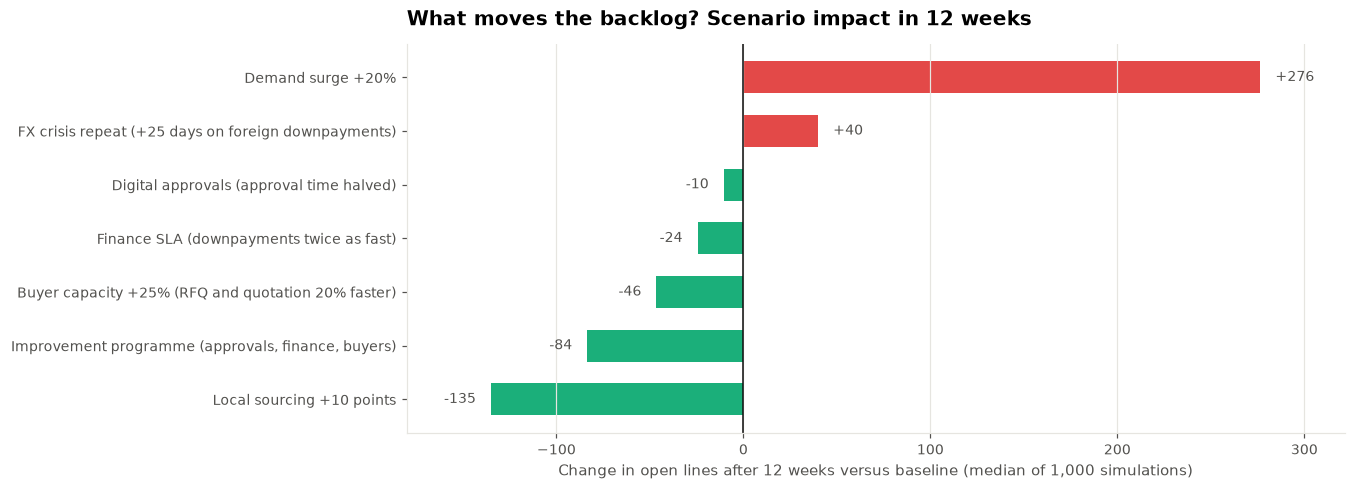

In [9]:
fig, ax = plt.subplots(figsize=(11, 4.6))
r = res.iloc[1:].sort_values("backlog change vs baseline")
colors = [SERIES[2] if v < 0 else SERIES[7] for v in r["backlog change vs baseline"]]
ax.barh(r.scenario, r["backlog change vs baseline"], color=colors, height=0.6)
ax.axvline(0, color=BRAND["ink"], lw=1)
for y, v in enumerate(r["backlog change vs baseline"]):
    ax.text(v + (8 if v >= 0 else -8), y, f"{v:+,.0f}", va="center", ha="left" if v >= 0 else "right", fontsize=9, color=BRAND["ink_2"])
vals = r["backlog change vs baseline"]
ax.set_xlim(vals.min() - 45, vals.max() + 45)
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_xlabel("Change in open lines after 12 weeks versus baseline (median of 1,000 simulations)")
ax.set_title("What moves the backlog? Scenario impact in 12 weeks")
plt.show()

**What we see.** (All scenarios use the same random numbers, so differences between them reflect the decision, not simulation noise,
even though each P10 to P90 range is wide.)

* **A demand surge of 20%** has by far the largest effect: about 275 more open lines (+14%) after 12 weeks. The pipeline cannot absorb a
  step change without more capacity. This is the risk behind further growth of the marine contract.
* **Moving 10 points of new demand to local suppliers** is the strongest single lever: about 135 fewer open lines (-7%), with no extra cash
  out, because local lines close in about six weeks instead of four months.
* **Internal improvements** help in proportion to how slow the step still is. Approvals are already fast after the 2024 policy, so halving
  them again removes only about 10 lines; faster downpayments remove about 25, extra buyer capacity about 47, and the combined programme
  about 80.
* **An FX crisis repeat** adds about 40 open lines and pushes USD 0.2 million of payments beyond the 12 weeks. Its full effect is larger
  and slower: a late downpayment delays the start of a production run that itself takes three months.

**So what.** Three recommendations follow, each quantified before any money is spent:

1. Build a **capacity plan for demand growth** (buyers and approvals) before the marine contract expands further.
2. **Qualify local suppliers** for the categories where they exist; it is the cheapest backlog reduction available.
3. Keep a **protected FX budget for critical foreign downpayments** to prevent a repeat of 2023.

## 7. Summary

| Use | Best approach | Evidence |
|---|---|---|
| Weekly demand by section | Structural demand simulator | Best MASE on 2024 and 2025, best calibration |
| Weekly cash out | Process simulator | Best MASE on 2025 (0.70) |
| Open backlog total | Theta or naive (simulator close behind) | Slow-moving stock series |
| What-if decisions | Process simulator | The only model that represents the stages a decision changes |
| Arrival date of open lines | Process simulator before approval, survival model after (notebook 12) | Line-level distributions |

**Next:** notebook 11 puts every model in one arena, tests significance and builds the decision scorecard.